# Example 1: scalar and vector inputs

This first tutorial walks through the whole ONNX2FMU workflow on a model small
enough to check by hand:

1. define a model in PyTorch and export it to ONNX;
2. write the model description that maps the ONNX nodes to FMU variables;
3. build the FMU;
4. simulate it with [FMPy](https://github.com/CATIA-Systems/FMPy) and compare
   the results with the original model.

The model takes one scalar and two vectors and combines them with basic
arithmetic. There is nothing to train, which keeps the focus on the tool.

To run the notebook yourself, clone the repository and install the extra
dependencies with `uv sync --all-extras` or `pip install ".[extra]"`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import torch
from torch import nn

## The model

The model has three inputs: a scalar `x1`, a vector `x2` with four elements
and a vector `x3` with five elements. It returns a single vector with ten
elements.

ONNX2FMU works with any ONNX graph, not only neural networks. Element-wise
arithmetic, slicing and concatenation are all fair game.

In [2]:
class ExampleModel(nn.Module):

    def forward(self, x1, x2, x3):
        x4 = x2 + x3[:4]      # 4 elements
        x5 = x2 - x3[:4]      # 4 elements
        x6 = x1 * x3[-1]      # 1 element
        x7 = x1 / x3[-1]      # 1 element
        return torch.cat([x4, x5, x6, x7])


model = ExampleModel()
model.eval()

# Example inputs. Their shapes are what the ONNX export records.
x1 = torch.tensor([1.0])
x2 = torch.randn(4)
x3 = torch.randn(5)

print("input shapes: ", x1.shape, x2.shape, x3.shape)
print("output shape: ", model(x1, x2, x3).shape)

input shapes:  torch.Size([1]) torch.Size([4]) torch.Size([5])
output shape:  torch.Size([10])


## Export to ONNX

The names passed as `input_names` and `output_names` become the names of the
graph nodes. They are the link between the ONNX model and the model
description, so choose names you will recognise.

Note that the scalar is exported with shape `(1,)`. ONNX2FMU needs every node
to have at least one dimension.

In [3]:
model_name = "example1"

torch.onnx.export(
    model,
    (x1, x2, x3),
    f"{model_name}.onnx",
    input_names=["scalar_input", "vector_input", "vector_input_discrete"],
    output_names=["output"],
    external_data=False,  # keep the whole model in a single file
    verbose=False,
)

onnx_model = onnx.load(f"{model_name}.onnx")
onnx.checker.check_model(onnx_model)

for node in list(onnx_model.graph.input) + list(onnx_model.graph.output):
    shape = [dim.dim_value for dim in node.type.tensor_type.shape.dim]
    print(f"{node.name:24s} shape {shape}")

scalar_input             shape [1]
vector_input             shape [4]
vector_input_discrete    shape [5]
output                   shape [10]


## The model description

The model description is a JSON file with some general information and the
list of inputs and outputs. Each entry refers to a node of the ONNX graph
through its `name`.

Two things to notice:

- The FMU is named after the `name` at the top of the model description. It
  does not have to match the name of the ONNX file.
- The output has `labels`: one human-readable text per element. They end up
  in the description of each FMU variable.

Every key is explained in the
[model description reference](../../docs/reference/model-description.md).

In [4]:
model_description = {
    "name": "example1",
    "description": "The model defines a simple example model with a scalar input and two vector inputs.",
    "FMIVersion": "2.0",
    "inputs": [
        {
            "name": "scalar_input",
            "description": "A scalar input to the model."
        },
        {
            "name": "vector_input",
            "description": "A vector of 4 input variables; variability is continuous by default."
        },
        {
            "name": "vector_input_discrete",
            "description": "A vector of 5 input variables; variability is continuous by default."
        }
    ],
    "outputs": [
        {
            "name": "output",
            "description": "The output array.",
            "labels": [f"Class{i}" for i in range(1, 11)]
        }
    ]
}

with open(f"{model_name}Description.json", "w", encoding="utf-8") as f:
    json.dump(model_description, f, indent=4)

## Build the FMU

`build` generates a small C project in `target_folder`, compiles it and
leaves `example1.fmu` in the current folder. The same thing can be done from
a shell with

```bash
onnx2fmu build example1.onnx example1Description.json temp
```

The first build downloads ONNX Runtime, so it takes a little longer than the
following ones. The `target_folder` is a scratch folder: it is deleted when
the build finishes.

In [5]:
from loguru import logger
from onnx2fmu.app import build

logger.disable("onnx2fmu")  # keep the notebook output short

build(
    model_path=f"{model_name}.onnx",
    model_description_path=f"{model_name}Description.json",
    target_folder="temp",
)

## What is inside the FMU

FMI tools work with named scalar signals, so ONNX2FMU exposes **one variable
per tensor element**. The name is the node name followed by the index of the
element. Let us read the list back from the FMU.

In [6]:
from fmpy import read_model_description

fmu_description = read_model_description(f"{model_name}.fmu")

pd.DataFrame(
    [
        {"name": v.name, "causality": v.causality, "type": v.type,
         "description": v.description}
        for v in fmu_description.modelVariables
    ]
)

,name,causality,type,description
0,time,independent,Real,Simulation time
1,scalar_input_0,input,Real,A scalar input to the model.
2,vector_input_0,input,Real,A vector of 4 input variables; variability is ...
3,vector_input_1,input,Real,A vector of 4 input variables; variability is ...
4,vector_input_2,input,Real,A vector of 4 input variables; variability is ...
5,vector_input_3,input,Real,A vector of 4 input variables; variability is ...
6,vector_input_discrete_0,input,Real,A vector of 5 input variables; variability is ...
7,vector_input_discrete_1,input,Real,A vector of 5 input variables; variability is ...
8,vector_input_discrete_2,input,Real,A vector of 5 input variables; variability is ...
9,vector_input_discrete_3,input,Real,A vector of 5 input variables; variability is ...


The three input nodes became ten input variables (1 + 4 + 5), and the
output node became ten output variables, each carrying its label.

## Reference data

To test the FMU we need input signals and the outputs we expect. We draw 100
random samples for the ten inputs and compute the expected output twice: with
NumPy and with the PyTorch model.

The inputs are saved to a CSV file whose column names are the FMU variable
names, plus a `time` column.

In [7]:
time_steps = 100
rng = np.random.default_rng(0)
data = rng.random((time_steps, 10))

scalar_input = data[:, 0]
vector_input_a = data[:, 1:5]
vector_input_b = data[:, 5:]

# The same calculation as the model, in NumPy
expected = np.hstack([
    vector_input_a + vector_input_b[:, :4],
    vector_input_a - vector_input_b[:, :4],
    (scalar_input * vector_input_b[:, -1])[:, None],
    (scalar_input / vector_input_b[:, -1])[:, None],
])

# The PyTorch model, one sample at a time
with torch.no_grad():
    y = torch.stack([
        model(
            torch.tensor(scalar_input[i:i + 1]),
            torch.tensor(vector_input_a[i]),
            torch.tensor(vector_input_b[i]),
        )
        for i in range(time_steps)
    ]).numpy()

print(f"largest difference between NumPy and PyTorch: {np.abs(y - expected).max():.2e}")

time = pd.Index(np.arange(time_steps), name="time")

input_columns = [v.name for v in fmu_description.modelVariables
                 if v.causality == "input"]
output_columns = [v.name for v in fmu_description.modelVariables
                  if v.causality == "output"]

pd.DataFrame(data, columns=input_columns, index=time).to_csv("Example1_in.csv")
pd.DataFrame(y, columns=output_columns, index=time).to_csv("Example1_ref.csv")

largest difference between NumPy and PyTorch: 0.00e+00


## Simulate the FMU

FMPy reads the input file as a structured array and feeds each column to the
variable with the same name. One step of the FMU is one evaluation of the
network, so we use a step of 1.

In [8]:
from fmpy import simulate_fmu

signals = np.genfromtxt("Example1_in.csv", delimiter=",", names=True)

results = simulate_fmu(
    f"{model_name}.fmu",
    start_time=0,
    stop_time=time_steps,
    output_interval=1,
    step_size=1,
    input=signals,
    validate=True,
)

df_fmu = pd.DataFrame(results).set_index("time")
df_fmu.head()

,output_0,output_1,output_2,output_3,output_4,output_5,output_6,output_7,output_8,output_9
time,,,,,,,,,,
0.0,1.182542,0.647609,0.746024,1.356895,-0.642969,-0.565662,-0.712969,0.269645,0.595605,0.681190
1.0,1.182542,0.647609,0.746024,1.356895,-0.642969,-0.565662,-0.712969,0.269645,0.595605,0.681190
2.0,0.178394,1.720583,0.575047,1.029367,-0.172917,-0.005775,-0.507876,0.429944,0.344851,1.930159
3.0,0.507961,1.667834,1.628025,1.300927,-0.259394,-0.326585,-0.333646,-0.070157,0.018421,0.043538
4.0,0.699163,0.620932,1.610976,1.459398,0.078680,-0.350739,-0.168000,-0.408689,0.246323,1.924136


The first row is recorded when the FMU is initialised, before it has taken
any step. From then on, the row at time `t + 1` is the model output for the
inputs at time `t`. We drop the first row and compare.

largest relative difference between FMU and PyTorch: 1.07e-07


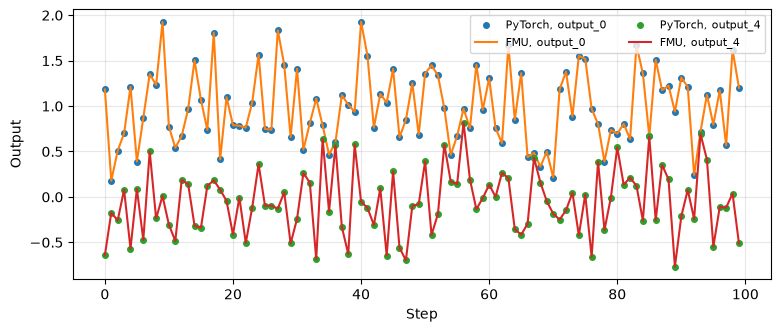

In [9]:
fmu_output = df_fmu.iloc[1:time_steps + 1].to_numpy()

relative_error = np.abs(fmu_output - y) / np.maximum(np.abs(y), 1.0)
print(f"largest relative difference between FMU and PyTorch: {relative_error.max():.2e}")

fig, ax = plt.subplots(figsize=(9, 3.5))
for column in [0, 4]:
    ax.plot(time, y[:, column], "o", ms=4, label=f"PyTorch, {output_columns[column]}")
    ax.plot(time, fmu_output[:, column], "-", label=f"FMU, {output_columns[column]}")
ax.set_xlabel("Step")
ax.set_ylabel("Output")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.show()

The FMU reproduces the PyTorch model. The small difference comes from
single-precision arithmetic: the FMU converts its inputs to 32-bit floats
before running the network, while the reference above was computed in double
precision.

## What next

- [Example 2](../example2/example2.ipynb) repeats the workflow in its
  shortest form.
- [Concepts](../../docs/concepts.md) explains how tensors become FMU
  variables in more detail.